## Assignment 2 Part 1


## Dataset Explanation

This dataset comes from an automobile company that has implemented different plans to enter new markets with their existing products (P1 ... P5). The goal is to segment customers effectively and apply communication strategies tailored to each group. The key information in the dataset is as follows:

- **Dataset Features**:
  - **ID**: A unique identifier for each customer.
  - **Gender**: The customer's gender (male, female).
  - **Ever_Married**: Whether the customer has ever been married (yes/no).
  - **Age**: The customer's age.
  - **Graduated**: Whether the customer has completed university studies (yes/no).
  - **Profession**: The customer's profession.
  - **Work_Experience**: The customer's years of work experience.
  - **Spending_Score**: A spending score indicating the customer's spending level (high, medium, low).
  - **Family_Size**: The size of the customer's family.
  - **Var_1**: An additional variable with unspecified features.
  - **Segmentation**: The segment the customer belongs to (A, B, C, D).

- **Customer Segmentation**:
  - The company has segmented customers into four groups: **A**, **B**, **C**, and **D**.
  - Each group has been targeted with a personalized outreach and communication strategy, leading to exceptional success in the application of these tactics.

- **Plans for New Markets**:
  - The company intends to apply the same segmentation strategy to new markets, using the model that has already proven successful.
  - A total of **2627 ( 20 % of test ) new potential customers** have been identified, and the same approach will be applied to them, expecting similar results.

This personalized, data-driven approach has allowed the company to increase the effectiveness of its marketing campaigns, and the expansion into new markets is expected to follow the same successful path.







# Assignment Index

1. **Data load**
   - Load the data 
   - Merge both data sets to have one in order to perform train and test split 
   - Brief view of how its is structured <br> <br>

2. **Data Cleaning**
   - Clean the data of missing values
   - Apply one-hot encoding for arrays and more techniques.
   - visualize the boxplots of each feature for anomalies 
   - Draw histograms of the numerical features to see distributions 
   - Correct or erase som error made in the features <br> <br>

3. **Start the procedure to start the NN**
   - Convert the data frame into Numpy Array
   - Apply Standard Scaler
   - Convert the data to tensors from PyTorch 
   - make the train and test split  <br> <br>

4. **Define the NN and its parameters**
   - Define the batch size and combine tensors datasets and data loaders
   - Define the NN architecture by a python class
   - Set its parameters, Loss function and Optimizer
   - Train and test the NN <br> <br>
   
5. **Tuning different hyperparameters** 
   - Change the number of layers and number of neurons 
   - Change the learning rate 
   - Explore the activations functions 
   - Change the batch size and see how it is affected 
   - Change number of epochs 
   - Change loss function and optimizer 

6. **Resume of all the conclusion i´ve got after hyperparameter tuning**




 #  1. LOAD THE DATA

In [ ]:
import pandas as pd

def merge_csv_files(train_path, test_path):
    """
    Lee dos archivos CSV y los concatena verticalmente.
    Devuelve un único DataFrame.
    """
    df_train = pd.read_csv(train_path)
    df_test = pd.read_csv(test_path)
    df_merged = pd.concat([df_train, df_test], axis=0, ignore_index=True)
    return df_merged



In [ ]:
data = merge_csv_files('../data/Train.csv', '../data/Test.csv')
#load data
display(data.head())


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


## 2. DATA CLEANING

# Missing values 
First we check in which features we have missing values or NaN values in order to fill it with the right technique 

In [ ]:
#Missing Values

# Check for missing values
missing_values = data.isnull().sum()
print("Missing values in each column:")
print(missing_values)

# check for NaN values
nan_values = data.isna().sum()
print("NaN values in each column:")
print(nan_values)

display(data.info())


Missing values in each column:
ID                    0
Gender                0
Ever_Married        190
Age                   0
Graduated           102
Profession          162
Work_Experience    1098
Spending_Score        0
Family_Size         448
Var_1               108
Segmentation          0
dtype: int64
NaN values in each column:
ID                    0
Gender                0
Ever_Married        190
Age                   0
Graduated           102
Profession          162
Work_Experience    1098
Spending_Score        0
Family_Size         448
Var_1               108
Segmentation          0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10695 entries, 0 to 10694
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               10695 non-null  int64  
 1   Gender           10695 non-null  object 
 2   Ever_Married     10505 non-null  object 
 3   Age              10695 non-null  int64  
 4 

None

we can plot the boxplots to the the distribution of the features we have missing values in to choose a proper method to deal with them 

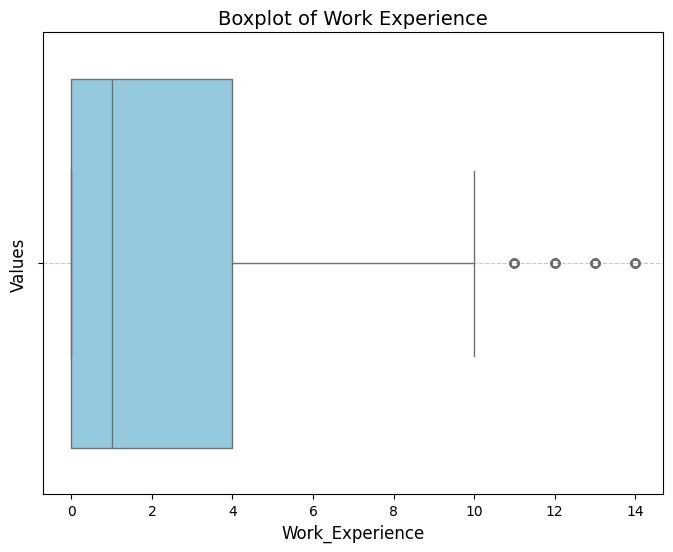

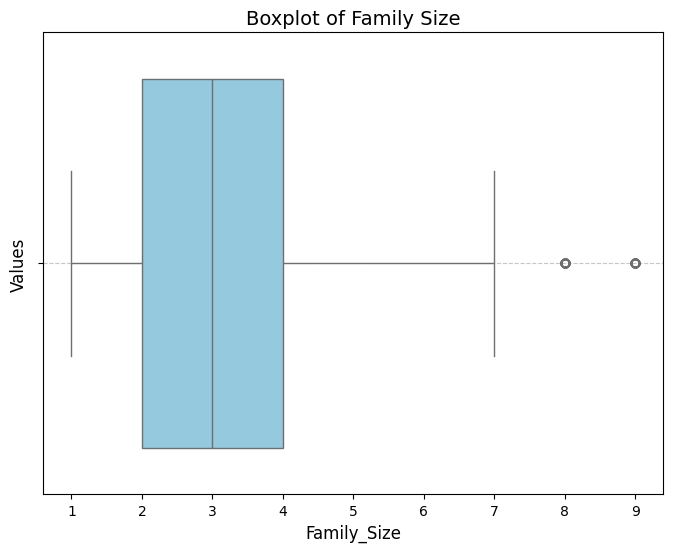

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_boxplot(df, feature, title=None, color="skyblue"):
    """
    Genera un boxplot para una característica específica de un DataFrame.

    Parámetros:
    -----------
    df : pd.DataFrame
        El DataFrame que contiene la característica a visualizar.
    feature : str
        El nombre de la columna (feature) para la cual se generará el boxplot.
    title : str, opcional
        El título del gráfico. Si no se proporciona, usará el nombre de la característica como título.
    color : str, default="skyblue"
        El color del boxplot.

    Retorna:
    --------
    None
    """
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df, x=feature, color=color)
    plt.title(title if title else f"Boxplot of {feature}", fontsize=14)
    plt.xlabel(feature, fontsize=12)
    plt.ylabel("Values", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.show()

plot_boxplot(data,'Work_Experience',title='Boxplot of Work Experience')
plot_boxplot(data,'Family_Size',title='Boxplot of Family Size')


as we se if we substitute with the mean it will be suitable for the distribution of data , and the categorical features we eliminate these rows

In [ ]:
# Fill missing values with the mean of the column
data['Work_Experience'].fillna(data['Age'].mean(), inplace=True)
data['Family_Size'].fillna(data['Family_Size'].mean(), inplace=True)

# Eliminate row of the missing values of the categorical features
# data = data.dropna(subset=['Ever_Married', 'Graduated', 'Profession', 'Var_1'])

data['Ever_Married'] = data['Ever_Married'].fillna(data['Ever_Married'].mode()[0])
data['Graduated'] = data['Graduated'].fillna(data['Graduated'].mode()[0])
data['Profession'] = data['Profession'].fillna(data['Profession'].mode()[0])
data['Var_1'] = data['Var_1'].fillna(data['Var_1'].mode()[0])



display(data.info())
data = data.drop(columns=['ID'], axis=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10695 entries, 0 to 10694
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               10695 non-null  int64  
 1   Gender           10695 non-null  object 
 2   Ever_Married     10695 non-null  object 
 3   Age              10695 non-null  int64  
 4   Graduated        10695 non-null  object 
 5   Profession       10695 non-null  object 
 6   Work_Experience  10695 non-null  float64
 7   Spending_Score   10695 non-null  object 
 8   Family_Size      10695 non-null  float64
 9   Var_1            10695 non-null  object 
 10  Segmentation     10695 non-null  object 
dtypes: float64(2), int64(2), object(7)
memory usage: 919.2+ KB


None

# Label encoder 
we apply these to the features called : Gender , Ever_married , Graduated , Profession , Spending score , Var_1

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

def label_encode_columns(df, column_names):
    """
    Performs Label Encoding on specified columns using Scikit-learn's LabelEncoder.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        column_names (list): A list of column names to encode.

    Returns:
        pd.DataFrame: A new DataFrame with the label-encoded columns.
    """
    # Initialize the label encoder
    encoder = LabelEncoder()

    # Apply Label Encoding to each specified column
    for column_name in column_names:
        df[column_name] = encoder.fit_transform(df[column_name])
    
    return df


# List of columns to encode
columns_names = ["Gender","Ever_Married","Graduated","Profession","Spending_Score","Var_1","Segmentation"]

data = label_encode_columns(data,columns_names)
display(data.head())




,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,1,0,22,0,5,1.000000,2,4.0,3,3
1,0,1,38,1,2,43.511828,0,3.0,3,0
2,0,1,67,1,2,1.000000,2,1.0,5,1
3,1,1,67,1,7,0.000000,1,2.0,5,1
4,0,1,40,1,3,43.511828,1,6.0,5,0


# One hot encoding 
As Var_1 has many categories that are other features that we dont know its names we must do one-hot encoding to simplify the work 

In [ ]:
def one_hot_encode_pandas(df, column_name, drop_first=False):
    """
    Performs One-Hot Encoding on a specified column using Pandas' get_dummies().

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        column_name (str): The name of the column to encode.
        drop_first (bool): Whether to drop the first category to avoid multicollinearity (default is False).

    Returns:
        pd.DataFrame: A new DataFrame with the one-hot encoded columns.
    """
    # Apply one-hot encoding
    df_encoded = pd.get_dummies(df, columns=[column_name], drop_first=drop_first).astype(int)
    return df_encoded

data = one_hot_encode_pandas(data, "Var_1", drop_first=True)

display(data.head())

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Segmentation,Var_1_1,Var_1_2,Var_1_3,Var_1_4,Var_1_5,Var_1_6
0,1,0,22,0,5,1,2,4,3,0,0,1,0,0,0
1,0,1,38,1,2,43,0,3,0,0,0,1,0,0,0
2,0,1,67,1,2,1,2,1,1,0,0,0,0,1,0
3,1,1,67,1,7,0,1,2,1,0,0,0,0,1,0
4,0,1,40,1,3,43,1,6,0,0,0,0,0,1,0


### Age Grouping Explanation

To improve model accuracy, the `Age` column was grouped into 6 categories based on observed segmentation patterns in the histogram:

- 0: 18–29
- 1: 30–39
- 2: 40–49
- 3: 50–59
- 4: 60–69
- 5: 70+

This binning simplifies the feature and helps the model detect age-related patterns more effectively.

In [ ]:
def age_binning_numeric(df, column='Age'):
    """
    Groups age into custom bins and assigns numeric labels.
    """
    bins = [17, 29, 39, 49, 59, 69, 100]  # age intervals
    labels = [0, 1, 2, 3, 4, 5]  # numeric labels for each bin
    df['Age_Group'] = pd.cut(df[column], bins=bins, labels=labels, right=True)
    df['Age_Group'] = df['Age_Group'].astype(int)  # convert to integer
    return df
data = age_binning_numeric(data, column='Age')

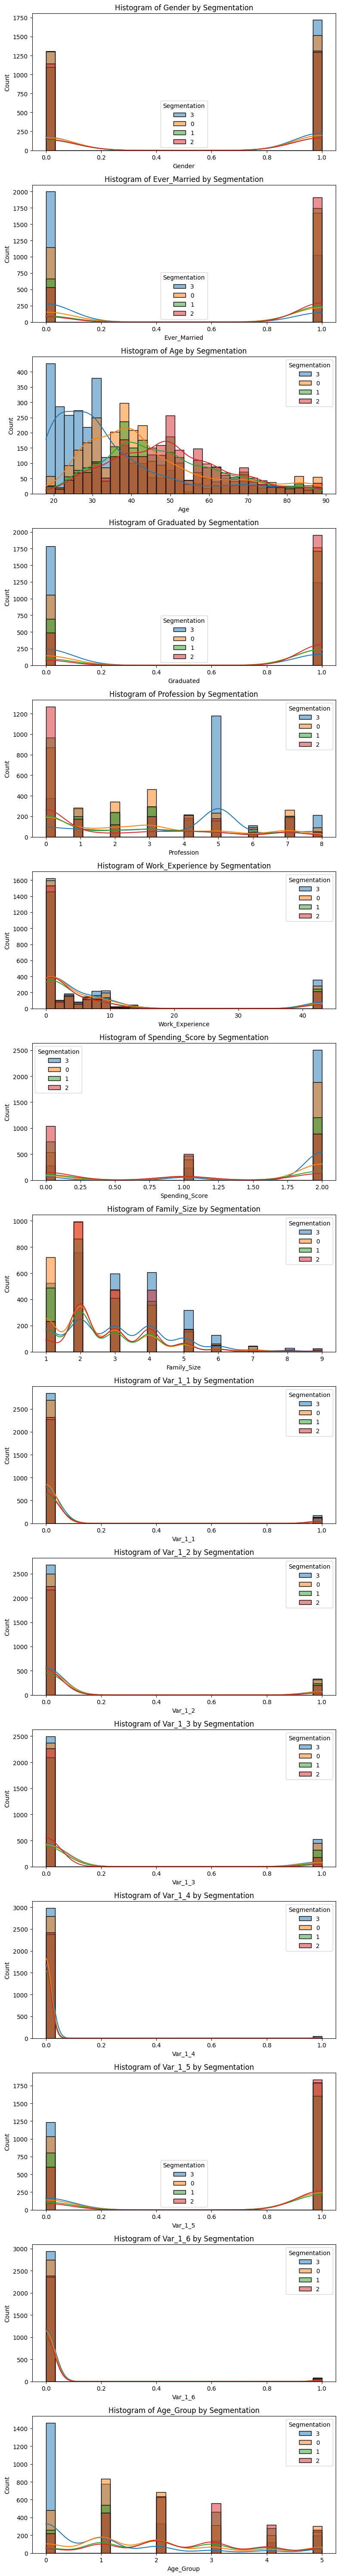

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_feature_histograms(df, target_feature, bins=30):
    """
    Genera histogramas de todas las características numéricas en función de una variable objetivo.

    Parámetros:
    - df: DataFrame de pandas
    - target_feature: Nombre de la columna objetivo (debe ser categórica o discreta)
    - bins: Número de bins para los histogramas
    """
    numeric_features = df.select_dtypes(include=['number']).columns
    numeric_features = [col for col in numeric_features if col != target_feature]
    
    unique_classes = df[target_feature].unique()
    num_features = len(numeric_features)
    
    fig, axes = plt.subplots(nrows=num_features, ncols=1, figsize=(8, 4 * num_features))
    
    if num_features == 1:
        axes = [axes]  # Asegura que axes sea iterable cuando hay solo una feature
    
    for ax, feature in zip(axes, numeric_features):
        for category in unique_classes:
            sns.histplot(df[df[target_feature] == category][feature], bins=bins, label=str(category), alpha=0.5, ax=ax, kde=True)
        
        ax.set_title(f'Histogram of {feature} by {target_feature}')
        ax.legend(title=target_feature)
    
    plt.tight_layout()
    plt.show()

# Plot histograms for all numeric features against the target variable
plot_feature_histograms(data, target_feature='Segmentation', bins=30)

In other to use PyTorch and testnosrv the objective feature must be the last to simplify steps 

In [ ]:
def move_column_to_end(df, column_name):
    """
    Mueve una columna específica al final del DataFrame.

    Args:
        df (pd.DataFrame): El DataFrame original.
        column_name (str): El nombre de la columna a mover.

    Returns:
        pd.DataFrame: DataFrame con la columna movida al final.
    """
    cols = [col for col in df.columns if col != column_name] + [column_name]
    return df[cols]
data = move_column_to_end(data, "Segmentation")

display(data.head())



,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1_1,Var_1_2,Var_1_3,Var_1_4,Var_1_5,Var_1_6,Age_Group,Segmentation
0,1,0,22,0,5,1,2,4,0,0,1,0,0,0,0,3
1,0,1,38,1,2,43,0,3,0,0,1,0,0,0,1,0
2,0,1,67,1,2,1,2,1,0,0,0,0,1,0,4,1
3,1,1,67,1,7,0,1,2,0,0,0,0,1,0,4,1
4,0,1,40,1,3,43,1,6,0,0,0,0,1,0,2,0


array([0, 1])

## 3. Start the procedure to start the NN

We convert the data frame into NumPy because PyTorch tensors require numerical input in array-like structure

In [ ]:
# Convertir DataFrame a arrays de NumPy
X = data.iloc[:, :-1].values  # Todas las columnas excepto la última (features)
y = data.iloc[:, -1].values   # Solo la última columna (target: Segmentation)

We apply standard scaler , with no need to reverse it due to that we are in a classification problem

In [ ]:
 # Standardize features to have zero mean and unit variance
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(X)

We convert these data to tensors with x to float 32 and y in long because for NN is more efficient and its convenient for the use of cross-entropy-loss later on 
And we train and test split 

In [ ]:

import torch
# Convert data to tensors for PyTorch compatibility
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.long)

from sklearn.model_selection import train_test_split
# Split dataset into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

## 4. Define NN and parameters 

we define the batch size and make use of the tensor data set with connection to its data loader in order to use the shuffle and batching to making it more efficient

In [ ]:
# Create DataLoader for batch processing
from torch.utils.data import DataLoader, TensorDataset
batch_size = 16 # Adjust as needed

train_dataset = TensorDataset(X_train, y_train)
test_dataset =  TensorDataset(X_test, y_test)

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader =  DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

Define the Nn with the init and forwatd with 2 layers 
### Neural Network Architecture Summary

The model has 2 fully connected (`Linear`) layers:

1. `fc1`: Input layer to hidden layer, followed by a ReLU activation.
2. `fc2`: Hidden layer to output layer, followed by a log-softmax activation.

Thus, the model consists of 2 layers plus their corresponding activations.

We initiate with different n of neurons to see the difference 

In [ ]:
# Define the neural network architecture
import torch.nn as nn
import torch.nn.functional as F
# Define the neural network architecture
class Costumer_Classifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim,hidden_dim)  # Input layer -> Hidden layer
        self.fc2 = nn.Linear(hidden_dim,output_dim)  # Hidden layer -> Output layer

    def forward(self, x):
        x = F.relu(self.fc1(x)) 
        x= self.fc2(x)
        return F.log_softmax(x, dim=1)  # Log softmax activation function for output
    

In [ ]:
# Model parameters and instantiation
import numpy as np
input_dim = X.shape[1]   # Number of features
hidden_dim1 = 8
hidden_dim2 = 16  # Number of neurons in the hidden layer
output_dim = len(np.unique(y)) 

model = Costumer_Classifier(input_dim, hidden_dim1, output_dim)
model2 = Costumer_Classifier(input_dim, hidden_dim2, output_dim)

# Define loss function and optimizer
import torch.optim as optim
criterion = nn.CrossEntropyLoss()  # Cross-entropy loss function
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam optimizer

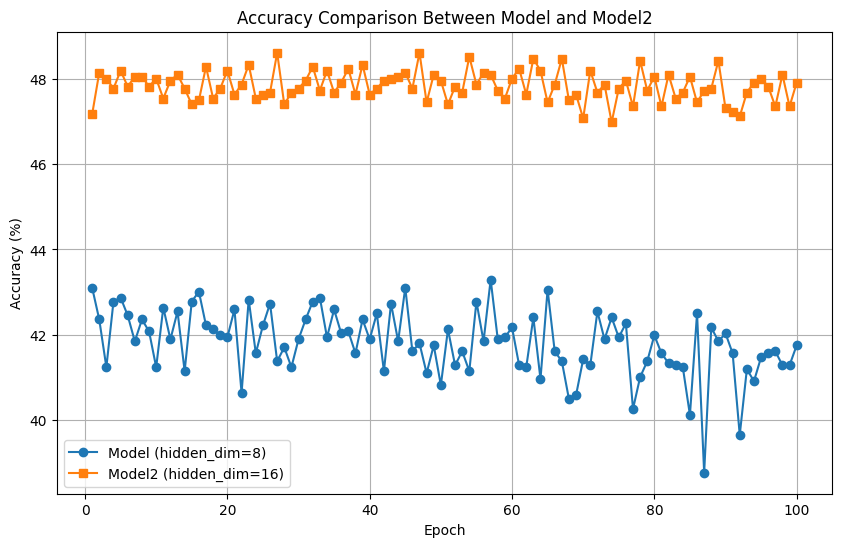


Final Accuracy Comparison:


'            Model Name  Final Accuracy (%)\n  Model (hidden_dim=8)           41.748481\nModel2 (hidden_dim=16)           47.919589'

In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim



# Two lists to store accuracy for each model
accuracy_list_model1 = []
accuracy_list_model2 = []

# Define loss function
criterion = nn.CrossEntropyLoss()

# --------------------------
# Train Model 1
# --------------------------
optimizer1 = optim.Adam(model.parameters(), lr=0.001)
epochs = 100
for epoch in range(epochs):
    model.train()
    for batch_X, batch_y in train_loader:
        optimizer1.zero_grad()
        output = model(batch_X)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer1.step()

    # Evaluate
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()
    accuracy = 100 * correct / total
    accuracy_list_model1.append(accuracy)

# --------------------------
# Train Model 2
# --------------------------
optimizer2 = optim.Adam(model2.parameters(), lr=0.001)
for epoch in range(epochs):
    model2.train()
    for batch_X, batch_y in train_loader:
        optimizer2.zero_grad()
        output = model2(batch_X)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer2.step()

    # Evaluate
    model2.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model2(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()
    accuracy = 100 * correct / total
    accuracy_list_model2.append(accuracy)

# --------------------------
# Plot comparison
# --------------------------
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs+1), accuracy_list_model1, label='Model (hidden_dim=8)', marker='o')
plt.plot(range(1, epochs+1), accuracy_list_model2, label='Model2 (hidden_dim=16)', marker='s')
plt.title("Accuracy Comparison Between Model and Model2")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()


import pandas as pd

# Create a DataFrame with the final accuracy of each model
final_accuracies = {
    "Model Name": ["Model (hidden_dim=8)", "Model2 (hidden_dim=16)"],
    "Final Accuracy (%)": [accuracy_list_model1[-1], accuracy_list_model2[-1]]
}

accuracy_df = pd.DataFrame(final_accuracies)

# Show table
print("\nFinal Accuracy Comparison:")
display(accuracy_df.to_string(index=False))

## 5. Hyperparameter tuning 

 ## 1: we start by see how its affect the model if i change the number of layers or n of neurons each layer :
    We try a 3 layer NN with different n of neurons in each layer 

Redefine the NN with a new train and test function 

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class CostumerClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc3 = nn.Linear(hidden_dim2, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return F.log_softmax(x, dim=1)

In [ ]:
def train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, epochs=100):
    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

    # Accuracy final
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    return 100 * correct / total  # Accuracy en %

And change the n of neurons in each layer ans compare its results in a panda table as we did in class

In [ ]:
architectures = [
    (8, 4),
    (16, 8),
    (32, 16),
    (64, 32),
    (128, 64)
]

results = []

for h1, h2 in architectures:
    model = CostumerClassifier(input_dim, h1, h2, output_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    
    acc = train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, epochs=50)
    
    results.append({
        'Hidden Layer 1': h1,
        'Hidden Layer 2': h2,
        'Accuracy (%)': acc
    })

In [ ]:
import pandas as pd

df_results = pd.DataFrame(results)
display(df_results)

,Hidden Layer 1,Hidden Layer 2,Accuracy (%)
0,8,4,48.667602
1,16,8,48.667602
2,32,16,47.592333
3,64,32,46.984572
4,128,64,46.750818


Now with 4 layers , lets see what we,ve got 

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class CostumerClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2,hidden_dim3, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc3 = nn.Linear(hidden_dim2, hidden_dim3)
        self.fc4 = nn.Linear(hidden_dim3, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return F.log_softmax(x, dim=1)

In [ ]:
def train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, epochs=100):
    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

    # Accuracy final
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    return 100 * correct / total  # Accuracy en %

In [ ]:
architectures = [
    (16, 8, 4),
    (32, 16, 8),
    (64, 32, 16),
    (128, 64, 32),
    (256, 128, 64)
]

results = []

for h1, h2,h3 in architectures:
    model = CostumerClassifier(input_dim, h1, h2,h3, output_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    
    acc = train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, epochs=50)
    
    results.append({
        'Hidden Layer 1': h1,
        'Hidden Layer 2': h2,
        'Hidden Layer 3': h3,
        'Accuracy (%)': acc
    })

In [ ]:
import pandas as pd

df_results = pd.DataFrame(results)
display(df_results)

,Hidden Layer 1,Hidden Layer 2,Hidden Layer 3,Accuracy (%)
0,16,8,4,47.498831
1,32,16,8,47.732585
2,64,32,16,46.797569
3,128,64,32,46.937821
4,256,128,64,43.899018


we,ve got that we achieve the best accuracy at the end with the **3 layer NN** with **18 , 8 neurons in the hidden layers** 

## 2. Change the learning rate and see what happens 
We are gonna select the best model out of the ones we have tried(3 layers ,(16,8) each hidden layer ) to see how the learning rate varies 
NOTE : we take as default architecture the one that gave us more results previously : 3layers (16,8) Neurons 

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class CostumerClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc3 = nn.Linear(hidden_dim2, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return F.log_softmax(x, dim=1)

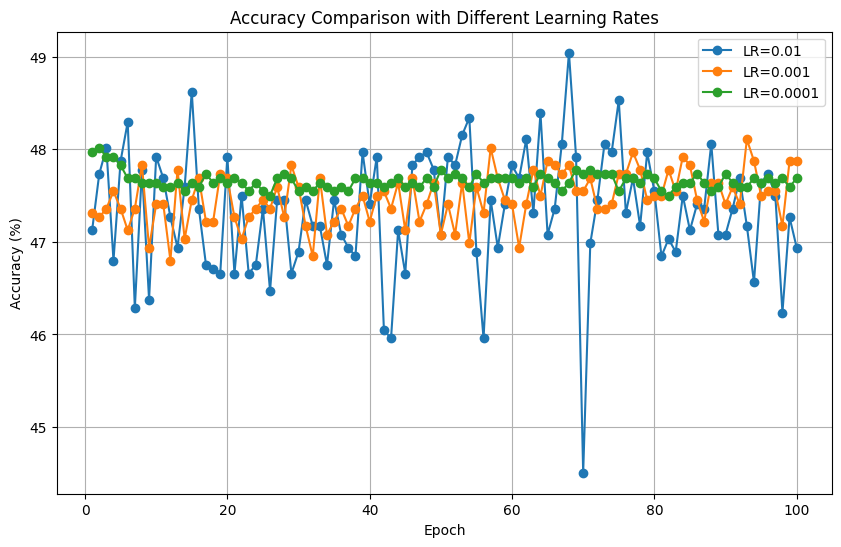


Final Accuracy Comparison for Different Learning Rates:

╒═════════════════╤══════════════════════╕
│   Learning Rate │   Final Accuracy (%) │
╞═════════════════╪══════════════════════╡
│          0.01   │              46.9378 │
├─────────────────┼──────────────────────┤
│          0.001  │              47.8728 │
├─────────────────┼──────────────────────┤
│          0.0001 │              47.6858 │
╘═════════════════╧══════════════════════╛


In [ ]:
# Import libraries
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn as nn

# List of learning rates to test
learning_rates = [0.01, 0.001, 0.0001]

# Store accuracy results for each learning rate
accuracy_lists = {lr: [] for lr in learning_rates} # like with the cache we did in class

# --------------------------
# Train Model with different learning rates
# --------------------------

# Initialize the model with 16 neurons in the hidden layer
model = CostumerClassifier(input_dim, 16, 8, output_dim)

# Set the number of epochs
epochs = 100

# Loop over the learning rates
for lr in learning_rates:
    # Set the optimizer with the current learning rate
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # List to store accuracy for the current learning rate
    accuracy_list = []

    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

        # Evaluate
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch_X, batch_y in test_loader:
                output = model(batch_X)
                _, predicted = torch.max(output.data, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()
        
        accuracy = 100 * correct / total
        accuracy_list.append(accuracy)

    # Store the accuracy for this learning rate
    accuracy_lists[lr] = accuracy_list

# --------------------------
# Plot comparison
# --------------------------
plt.figure(figsize=(10, 6))

# Plot each learning rate's accuracy
for lr, accuracy_list in accuracy_lists.items():
    plt.plot(range(1, epochs+1), accuracy_list, label=f'LR={lr}', marker='o')

plt.title("Accuracy Comparison with Different Learning Rates")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------
# Print final accuracy comparison
# --------------------------
from tabulate import tabulate
import pandas as pd

# Create a DataFrame with final accuracies for comparison
final_accuracies = {
    "Learning Rate": [str(lr) for lr in learning_rates],
    "Final Accuracy (%)": [accuracy_lists[lr][-1] for lr in learning_rates]
}

accuracy_df = pd.DataFrame(final_accuracies)

# Pretty print using tabulate
print("\nFinal Accuracy Comparison for Different Learning Rates:\n")
print(tabulate(accuracy_df, headers="keys", tablefmt="fancy_grid", showindex=False))


## 3: hyperparameter of activation functions 
we can try the model with these types : nn.ReLU(), nn.Sigmoid(), nn.Tanh()

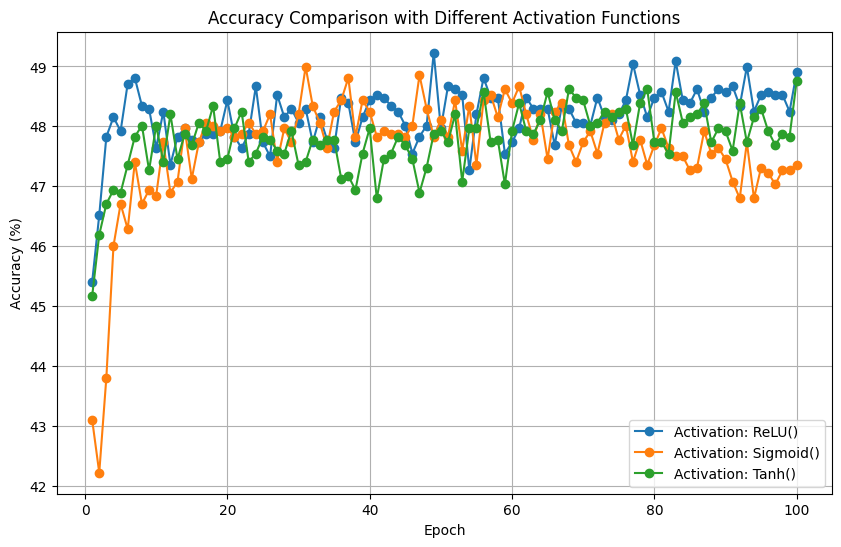


Final Accuracy Comparison for Different Activation Functions:

╒═══════════════════════╤══════════════════════╕
│ Activation Function   │   Final Accuracy (%) │
╞═══════════════════════╪══════════════════════╡
│ ReLU()                │              48.9014 │
├───────────────────────┼──────────────────────┤
│ Sigmoid()             │              47.3586 │
├───────────────────────┼──────────────────────┤
│ Tanh()                │              48.7611 │
╘═══════════════════════╧══════════════════════╛


In [ ]:
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define the model with a customizable activation function
# Define the model with three layers and customizable activation
class Costumer_Classifier(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim, activation_function=nn.ReLU()):
        super(Costumer_Classifier, self).__init__()
        
        # Define layers
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc3 = nn.Linear(hidden_dim2, output_dim)
        
        # Activation function (can be ReLU, Sigmoid, Tanh, etc.)
        self.activation = activation_function

    def forward(self, x):
        x = self.activation(self.fc1(x))  # First hidden layer
        x = self.activation(self.fc2(x))  # Second hidden layer
        x = self.fc3(x)  # Output layer
        return x

# List of activation functions to test
activation_functions = [nn.ReLU(), nn.Sigmoid(), nn.Tanh()]

# Store accuracy results for each activation function
accuracy_lists_activations = {}

# Number of epochs
epochs = 100

# Train and evaluate the model for each activation function
for activation_func in activation_functions:
    # Initialize the model with the current activation function
    model = Costumer_Classifier(input_dim, 16,8, output_dim, activation_function=activation_func)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # List to store accuracy for the current activation function
    accuracy_list = []

    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

        # Evaluate the model
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch_X, batch_y in test_loader:
                output = model(batch_X)
                _, predicted = torch.max(output.data, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()

        accuracy = 100 * correct / total
        accuracy_list.append(accuracy)

    # Store the accuracy for this activation function
    accuracy_lists_activations[str(activation_func)] = accuracy_list

# --------------------------
# Plot comparison of accuracy
# --------------------------

plt.figure(figsize=(10, 6))

# Plot each activation function's accuracy
for activation_func, accuracy_list in accuracy_lists_activations.items():
    plt.plot(range(1, epochs+1), accuracy_list, label=f'Activation: {activation_func}', marker='o')

plt.title("Accuracy Comparison with Different Activation Functions")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------
# Print final accuracy comparison
# --------------------------

from tabulate import tabulate
import pandas as pd

# Create a DataFrame with final accuracies for comparison
final_accuracies_activations = {
    "Activation Function": [str(activation_func) for activation_func in activation_functions],
    "Final Accuracy (%)": [accuracy_lists_activations[str(activation_func)][-1] for activation_func in activation_functions]  # (-1) = last value of the list
}

accuracy_df_activations = pd.DataFrame(final_accuracies_activations)

# Pretty print using tabulate
print("\nFinal Accuracy Comparison for Different Activation Functions:\n")
print(tabulate(accuracy_df_activations, headers='keys', tablefmt='fancy_grid', showindex=False))

## 4.Change the batch size we use values like : 16,32,64,and 128

In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

# Define the batch sizes to test
batch_sizes = [16, 32, 64, 128]

# Dictionary to store accuracy results for each batch size
accuracy_lists = {}

# Number of training epochs
epochs = 100

# Loop over each batch size
for batch_size in batch_sizes:

    # Reload data using the current batch size
    train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
    test_loader =  DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

    # Reinitialize the model for a fair comparison
    model = Costumer_Classifier(input_dim, 16,8 ,output_dim)

    # Define optimizer and loss function
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # List to store accuracy for each epoch
    accuracy_list = []

    # Training loop
    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

        # Evaluation loop
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch_X, batch_y in test_loader:
                output = model(batch_X)
                _, predicted = torch.max(output.data, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()

        accuracy = 100 * correct / total
        accuracy_list.append(accuracy)

    # Save accuracy list for this batch size
    accuracy_lists[batch_size] = accuracy_list

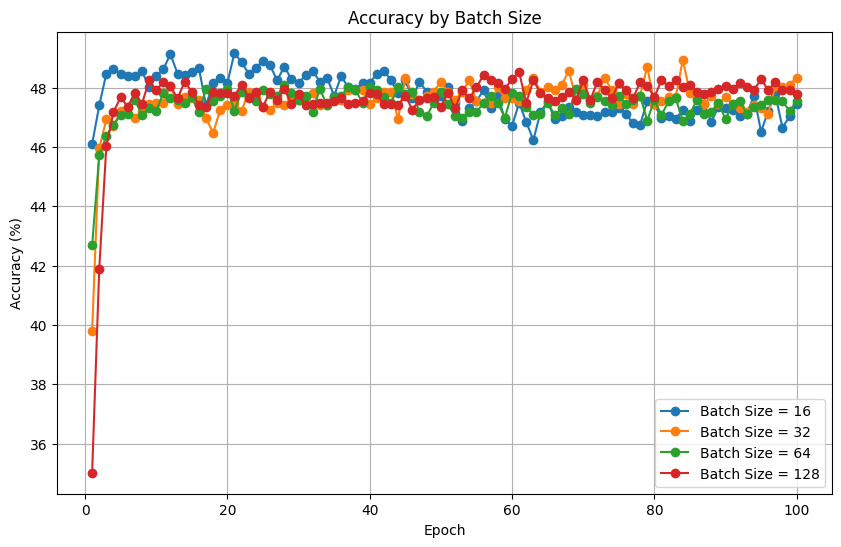

In [ ]:
plt.figure(figsize=(10, 6))

# Plot accuracy curves for each batch size
for batch_size, acc in accuracy_lists.items():
    plt.plot(range(1, epochs+1), acc, label=f'Batch Size = {batch_size}', marker='o')

plt.title("Accuracy by Batch Size")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from tabulate import tabulate

# Create a summary table for final accuracy
final_accuracy_summary = {
    "Batch Size": batch_sizes,
    "Final Accuracy (%)": [accuracy_lists[bs][-1] for bs in batch_sizes]
}

df_batch = pd.DataFrame(final_accuracy_summary)

# Display in nice visual table format
print("\nFinal Accuracy Comparison by Batch Size:\n")
print(tabulate(df_batch, headers='keys', tablefmt='fancy_grid', showindex=False))


Final Accuracy Comparison by Batch Size:

╒══════════════╤══════════════════════╕
│   Batch Size │   Final Accuracy (%) │
╞══════════════╪══════════════════════╡
│           16 │              47.4521 │
├──────────────┼──────────────────────┤
│           32 │              48.3403 │
├──────────────┼──────────────────────┤
│           64 │              47.5456 │
├──────────────┼──────────────────────┤
│          128 │              47.7793 │
╘══════════════╧══════════════════════╛


## 5. See what happens if we change the n of epochs

In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

# Epoch values to test
epoch_values = [10, 30, 50, 100, 150]

# Store final accuracy for each epoch count
final_accuracies_epochs = []

# Fixed batch size and learning rate
batch_size = 32
learning_rate = 0.001

# Create DataLoader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader =  DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Loop through each epoch count
for num_epochs in epoch_values:
    # Reinitialize the model for each run
    model = Costumer_Classifier(input_dim, 16,8, output_dim)

    # Set optimizer and loss
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()

    # Train the model for the current number of epochs
    for epoch in range(num_epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluate model
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    # Save final accuracy for this number of epochs
    final_accuracy = 100 * correct / total
    final_accuracies_epochs.append(final_accuracy)

In [ ]:
from tabulate import tabulate

# Create DataFrame to compare final accuracy vs. number of epochs
df_epochs = pd.DataFrame({
    "Epochs": epoch_values,
    "Final Accuracy (%)": final_accuracies_epochs
})

# Display the result in a nice table format
print("\nFinal Accuracy Comparison for Different Epoch Counts:\n")
print(tabulate(df_epochs, headers='keys', tablefmt='fancy_grid', showindex=False))


Final Accuracy Comparison for Different Epoch Counts:

╒══════════╤══════════════════════╕
│   Epochs │   Final Accuracy (%) │
╞══════════╪══════════════════════╡
│       10 │              47.8728 │
├──────────┼──────────────────────┤
│       30 │              47.8728 │
├──────────┼──────────────────────┤
│       50 │              47.5923 │
├──────────┼──────────────────────┤
│      100 │              48.0598 │
├──────────┼──────────────────────┤
│      150 │              46.8911 │
╘══════════╧══════════════════════╛


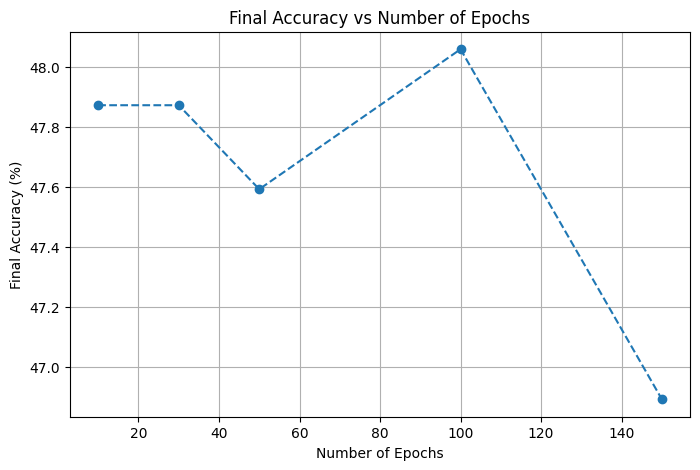

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(epoch_values, final_accuracies_epochs, marker='o', linestyle='--')
plt.title("Final Accuracy vs Number of Epochs")
plt.xlabel("Number of Epochs")
plt.ylabel("Final Accuracy (%)")
plt.grid(True)
plt.show()

## 6. change of the loss function and optimizer 

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

# Combinations of (loss_function, optimizer_name)
combinations = [
    ("CrossEntropy", "Adam"),
    ("CrossEntropy", "SGD"),
    ("NLLLoss", "Adam"),
    ("NLLLoss", "SGD")
]

# Epochs and batch size
epochs = 100
batch_size = 32
learning_rate = 0.001

# Store final accuracies
results = []

# DataLoader (asumes ya definidos: train_dataset, test_dataset)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader =  DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Loop through each (loss, optimizer) combination
for loss_name, opt_name in combinations:
    # Model
    model = Costumer_Classifier(input_dim, 16,8, output_dim)

    # Loss function
    if loss_name == "CrossEntropy":
        criterion = nn.CrossEntropyLoss()
    elif loss_name == "NLLLoss":
        criterion = nn.NLLLoss()
        model = nn.Sequential(  # Redefinir el modelo para aplicar log_softmax
            model,
            nn.LogSoftmax(dim=1)
        )

    # Optimizer
    if opt_name == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    elif opt_name == "SGD":
        optimizer = optim.SGD(model.parameters(), lr=learning_rate)

    # Train
    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            output = model(batch_X)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluate
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    # Save results
    accuracy = 100 * correct / total
    results.append((loss_name, opt_name, accuracy))

from tabulate import tabulate

# Assuming results = [(loss1, opt1, acc1), (loss2, opt2, acc2), ...]
print(tabulate(results, headers=["Loss Function", "Optimizer", "Accuracy (%)"], tablefmt="fancy_grid")) 

╒═════════════════╤═════════════╤════════════════╕
│ Loss Function   │ Optimizer   │   Accuracy (%) │
╞═════════════════╪═════════════╪════════════════╡
│ CrossEntropy    │ Adam        │        48.0598 │
├─────────────────┼─────────────┼────────────────┤
│ CrossEntropy    │ SGD         │        45.3483 │
├─────────────────┼─────────────┼────────────────┤
│ NLLLoss         │ Adam        │        47.1716 │
├─────────────────┼─────────────┼────────────────┤
│ NLLLoss         │ SGD         │        46.8443 │
╘═════════════════╧═════════════╧════════════════╛


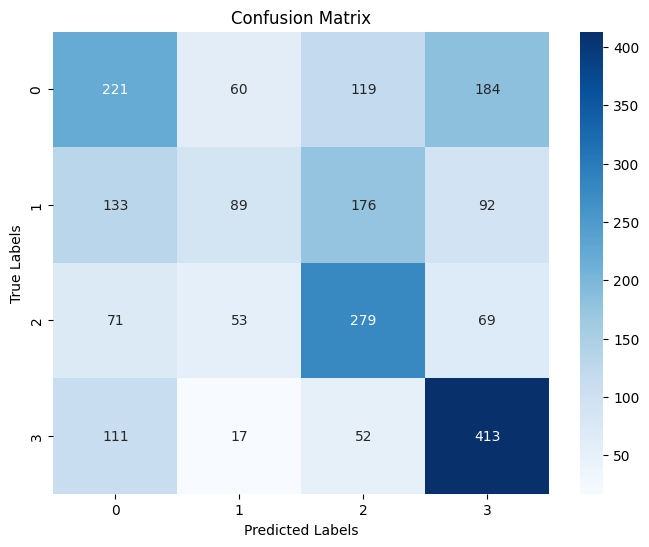


Confusion Matrix:
[[221  60 119 184]
 [133  89 176  92]
 [ 71  53 279  69]
 [111  17  52 413]]


In [ ]:
import torch
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Initialize model and make predictions
model.eval()  # Set the model to evaluation mode

# Store true labels and predicted labels
true_labels = []
predicted_labels = []

# Loop through the test data to get true and predicted labels
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        output = model(batch_X)
        _, predicted = torch.max(output.data, 1)  # Get the predicted class
        true_labels.extend(batch_y.numpy())  # Append true labels
        predicted_labels.extend(predicted.numpy())  # Append predicted labels

# Compute confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(cm.shape[1]), yticklabels=range(cm.shape[0]))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Print out the confusion matrix for analysis
print("\nConfusion Matrix:")
print(cm)

# Model Definition with 2 Layers, 8 Neurons, Sigmoid Activation, Learning Rate of 0.0001, Batch Size of 16, and 100 Epochs

In this notebook, we will define and train a neural network with the following parameters:
- **Model Architecture**: 3 hidden layers, with 18,8 neurons in each layer.
- **Activation Function**: Relu.
- **Learning Rate**: 0.001.
- **Batch Size**: 32.
- **Epochs**: 100.
- **Loss Function**: CrossentropyLoss
- **Optimizer**: Adam.






In [ ]:
# Create DataLoader for batch processing
from torch.utils.data import DataLoader, TensorDataset
batch_size = 32

train_dataset = TensorDataset(X_train, y_train)
test_dataset =  TensorDataset(X_test, y_test)

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader =  DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Define the neural network architecture

import torch.nn as nn
import torch.nn.functional as F
# Define the neural network architecture

class CostumerClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc3 = nn.Linear(hidden_dim2, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return F.log_softmax(x, dim=1)

# Model parameters and instantiation
import numpy as np
input_dim = X.shape[1]   # Number of features
hidden_dim1 = 8
hiddem_dim2 = 16  # Number of neurons in the hidden layer
output_dim = len(np.unique(y)) # Number of unique wine categories

model = Costumer_Classifier(input_dim, hidden_dim1,hidden_dim2, output_dim)

# Define loss function and optimizer
import torch.optim as optim
criterion = nn.CrossEntropyLoss()  # Cross-entropy loss function
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam optimizer


Epoch [10/100], Loss: 1.1628, Accuracy: 47.78%
Epoch [20/100], Loss: 1.1613, Accuracy: 48.53%
Epoch [30/100], Loss: 1.1600, Accuracy: 48.20%
Epoch [40/100], Loss: 1.1596, Accuracy: 48.06%
Epoch [50/100], Loss: 1.1594, Accuracy: 48.39%
Epoch [60/100], Loss: 1.1580, Accuracy: 48.25%
Epoch [70/100], Loss: 1.1583, Accuracy: 48.62%
Epoch [80/100], Loss: 1.1575, Accuracy: 48.11%
Epoch [90/100], Loss: 1.1577, Accuracy: 48.71%
Epoch [100/100], Loss: 1.1566, Accuracy: 48.85%


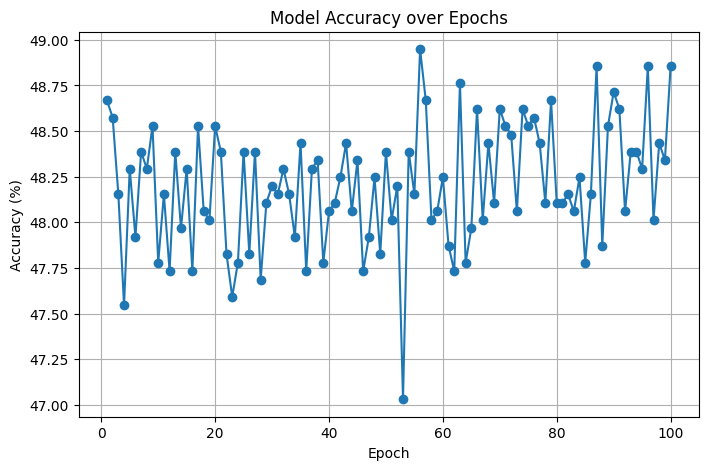

In [ ]:
import matplotlib.pyplot as plt

# List to store accuracy over epochs
accuracy_list = []

epochs = 100
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        output = model(batch_X)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    # Evaluate at each epoch
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            output = model(batch_X)
            _, predicted = torch.max(output.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()
    
    accuracy = 100 * correct / total
    accuracy_list.append(accuracy)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {total_loss/len(train_loader):.4f}, Accuracy: {accuracy:.2f}%")

# Plot accuracy over epochs
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs+1), accuracy_list, marker='o')
plt.title("Model Accuracy over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.show()

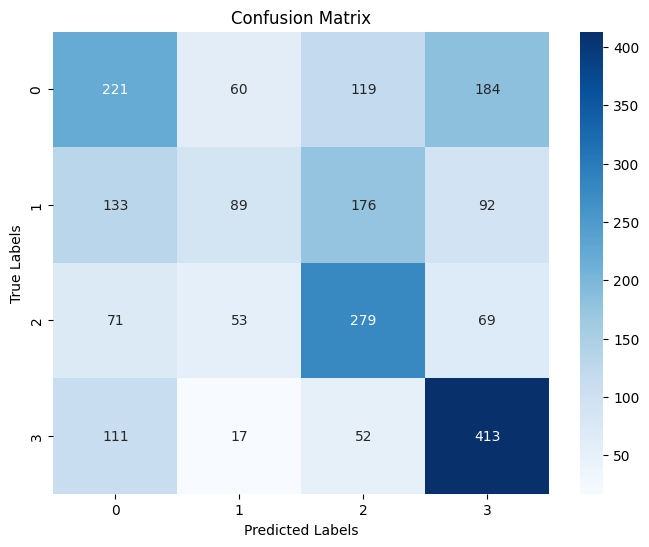


Confusion Matrix:
[[221  60 119 184]
 [133  89 176  92]
 [ 71  53 279  69]
 [111  17  52 413]]


In [ ]:
# Compute confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(cm.shape[1]), yticklabels=range(cm.shape[0]))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Print out the confusion matrix for analysis
print("\nConfusion Matrix:")
print(cm)

# Hyperparameter Analysis for Classification Model

NOTE : All the testing has been done with a base model of a NN with 3 layers and 16 and 8 neurons in the hidden layers by default with ReLU, just to clarify

## Introduction

In this analysis, we tested different hyperparameter combinations to optimize the performance of our classification model. The hyperparameters we considered include **learning rate**, **batch size**, **activation function**, **number of layers**, and **number of neurons per layer**. Below is a brief summary of the function and impact of each hyperparameter on the model.

## Hyperparameter of N of layers and neurons per layer  
To the NN we can change and vary the number of layers it has to process and the N of neurons. In theory, single-layer models are faster to train but may not capture patterns in complex data, but this changes with multilayer.

We have tried single layers with 8, 16 neurons and multilayer with : 2 layers and 3 layers and 4 layers  each with different combinations of neurons. At the end the best for us was the three layer with **16 and 8 Neurons**

## Hyperparameter 1: Learning Rate

The **learning rate** is one of the most important parameters when training a machine learning model. It controls the size of the steps the optimizer takes at each iteration. If the learning rate is too high, the model might miss the best solutions, while if it's too low, the training might become too slow or stall. 

### Results

We tested three learning rates: 0.01, 0.001, and 0.0001. In general, a lower learning rate resulted in better accuracy, but also made the training slower. The learning rate of **0.001** performed the best overall, achieving the highest final accuracy over all the tests we did 

## Hyperparameter 2: Batch Size

**Batch size** is the number of samples processed before the model updates its parameters. A small batch size can lead to faster learning, but might result in higher variability in the accuracy. A larger batch size usually reduces variability but makes the training slower.

### Results

We tested different batch sizes, such as 16, 32, 64 and 128. The results showed that a batch size of **32** provided a good balance between training time and final accuracy.

## Hyperparameter 3: Activation Function

**Activation functions** are crucial because they determine how neurons are "activated" in each layer of the model. We tested **ReLU**, **Sigmoid** and **Tanh**. ReLU is more common in deep networks because it helps avoid the vanishing gradient problem, while Sigmoid is often useful in simpler models.

### Results

The **Relu** activation function worked well with our three-layer model. This is because ReLU allows for a greater flow of gradients during training, enabling faster adjustments of weights.

## Hyperparameter 4: Number of Epochs

The **number of epochs** is the number of times the model sees the entire dataset during training. Generally, more epochs allow the model to learn better, but it can also lead to overfitting if the model learns the training data too well or vice versa: underfitting.

### Results

We tested with 10, 30, 50, 100 and 150 epochs. The model with **100 epochs** showed higher final accuracy, but also took significantly more time to converge. The model with 30 epochs performed well too, but seemed to reach its performance limit more quickly.

## Hyperparameter 5: Loss Function and Optimizer

We tested two combinations of **loss function** (CrossEntropyLoss and NLLLoss) and **optimizers** (Adam and SGD). The loss function measures how far the model's predictions are from the actual labels. Optimizers like **Adam** and **SGD** update the model's weights based on the gradients calculated.

### Results

The combination of **CrossEntropyLoss** with **Adam** optimizer was the most effective in terms of final accuracy. Adam adapts the learning rate during training, which helps improve convergence.
In average , this combination was the one that gave me the most effective results ( more near to 49) but ind the last compilation it was better the ( NNlloss and adam) but i choose the other combination because it was more consistent.

## Final Conclusions

Among all the hyperparameters we tested, the combination of **learning rate of 0.001**, **batch size of 32**, **Relu** activation function, and **100 epochs** achieved the best performance for our classification model. However, it's important to note that the **number of layers** and **number of neurons** also play a significant role in the model's performance, and should be adjusted based on the complexity of the data and the specific problem at hand.

## Final accuracy and analysis of results  

This analysis is complex due to the random test and batch it chooses, so in each iteration it will give a different result, but these are my conclusions after doing several trials at this large code.

This is why I reached only **48.85%** at my final model when the max I have reached was **49.4%** accuracy, which is one of the best results I have found by other coders on this complex dataset, so I’m satisfied with the result.

Watching the confusion matrix we noticed that the problem was with the **group 1 (B)** of customers that was interpreted by the NN as **C** and **A** a lot of times, so this is the key fact for such a low accuracy — but it’s a dataset problem because it is such a complex one!



## Chat GPT help

I have used the help of this ai with two based process:

1. With all the hyperparameters tuning at the time of doing the loops for each hyperparameters and putting all the data into an array and then plot it i have done that with the help of this , but i can assure that i have learned how it does  being the most difficult part this one : 

    Before starting the training process, an empty dictionary accuracy_lists_activations = {} is initialized to store the accuracy results for each activation function. The key for this dictionary is the string representation of the activation function (str(activation_func)), and the value is a list of accuracy values recorded during each epoch.

    The list accuracy_list = [] is created inside the loop for each activation function. This list will store the accuracy values obtained at the end of each epoch.
    After the training and evaluation for each activation function are completed, the final accuracy_list (which now contains the accuracy for each epoch) is saved in the dictionary accuracy_lists_activations. The key for this dictionary is the string representation of the activation function, which allows easy identification of the activation function used for each set of results.

    Finally, after all the activation functions have been tested, we create a DataFrame from the dictionary accuracy_lists_activations. This DataFrame contains the activation functions and their respective final accuracy after 100 epochs, which is then displayed as a nicely formatted table using the tabulate library.

    final_accuracies_activations = {
    "Activation Function": [str(activation_func) for activation_func in activation_functions],
    "Final Accuracy (%)": [accuracy_lists_activations[str(activation_func)][-1] for activation_func in activation_functions]  # (-1) = last value of the list

2. And the tabulate idea of representing more clearly the information was idea of chat gpt as well 

3. And all the plot as well because im very bad at using the matplot.lib
